In [1]:
import cv2
import tensorflow.compat.v1 as tf
tf.disable_v2_behavior()
import argparse
import numpy as np
import os
import pdb
import time
import matplotlib.pyplot as plt
import sys

Instructions for updating:
non-resource variables are not supported in the long term


In [2]:
# ############### Global Parameters ###############
demo_path = '../Dataset/features/test/'
default_model_path = '../demo_model/demo_model'
video_path = '../Dataset/videos/'

In [10]:
# ############## Train Parameters #################

# # Parameters
learning_rate = 0.0001
batch_size = 10
test_num = 46

# Network Parameters
n_input = 4096 # fc6 or fc7(1*4096)
n_detection = 20 # number of object of each image (include image features)
n_hidden = 512 # hidden layer num of LSTM
n_img_hidden = 256 # embedding image features 
n_att_hidden = 256 # embedding object features
n_classes = 2 # has accident or not
n_frames = 100 # number of frame in each video 

In [8]:
def vis(model_path, max_batches=None):
    print("Building model...")
    tf.reset_default_graph()
    x,keep,y,optimizer,loss,lstm_variables,soft_pred,all_alphas = build_model()
    sess = tf.InteractiveSession(config=tf.ConfigProto(allow_soft_placement=True))
    sess.run(tf.global_variables_initializer())

    print(f"Loading demo model from: {model_path}")
    tf.train.Saver().restore(sess, model_path)
    print("Model loaded. Running on TEST batches...\n")

    last = test_num if max_batches is None else min(test_num, 1 + max_batches)
    for num_batch in range(1, last):
        file_name = '%03d' % num_batch
        all_data = np.load(demo_path + 'batch_' + file_name + '.npz')
        data, labels = all_data['data'], all_data['labels']
        det, ID = all_data['det'], all_data['ID']
        print(f"=== Batch {num_batch} ===")
        pred, weight = sess.run([soft_pred, all_alphas],
                                feed_dict={x: data, y: labels, keep: [0.0]})
        for i in range(len(ID)):
            if labels[i][1] == 1:                      # accident videos only
                vid = ID[i].decode('utf-8') if isinstance(ID[i], bytes) else str(ID[i])
                print(f"   plotting accident video {i}  (ID {vid})")
                plt.figure(figsize=(12, 4))
                plt.plot(pred[i, 0:90], linewidth=3)
                plt.ylim(0, 1); plt.xlabel('Frame'); plt.ylabel('Probability')
                plt.title(f'Batch {num_batch} | video {i} | ID {vid} | ACCIDENT')
                plt.show()                
                file_name = ID[i].decode('utf-8') if isinstance(ID[i], bytes) else str(ID[i])
                bboxes = det[i]
                new_weight = weight[:,:,i]*255
                counter = 0 
                cap = cv2.VideoCapture(video_path+file_name+'.mp4') 
                ret, frame = cap.read()
                while(ret):
                    attention_frame = np.zeros((frame.shape[0],frame.shape[1]),dtype = np.uint8)
                    now_weight = new_weight[counter,:]
                    new_bboxes = bboxes[counter,:,:]
                    index = np.argsort(now_weight)
                    for num_box in index:
                        if now_weight[num_box]/255.0>0.4:
                            cv2.rectangle(frame,(new_bboxes[num_box,0],new_bboxes[num_box,1]),(new_bboxes[num_box,2],new_bboxes[num_box,3]),(0,255,0),3)
                        else:
                            cv2.rectangle(frame,(new_bboxes[num_box,0],new_bboxes[num_box,1]),(new_bboxes[num_box,2],new_bboxes[num_box,3]),(255,0,0),2)
                        font = cv2.FONT_HERSHEY_SIMPLEX
                        cv2.putText(frame,str(round(now_weight[num_box]/255.0*10000)/10000),(new_bboxes[num_box,0],new_bboxes[num_box,1]), font, 0.5,(0,0,255),1,cv2.CV_AA)
                        attention_frame[int(new_bboxes[num_box,1]):int(new_bboxes[num_box,3]),int(new_bboxes[num_box,0]):int(new_bboxes[num_box,2])] = now_weight[num_box]

                    attention_frame = cv2.applyColorMap(attention_frame, cv2.COLORMAP_HOT)
                    dst = cv2.addWeighted(frame,0.6,attention_frame,0.4,0)
                    cv2.putText(dst,str(counter+1),(10,30), font, 1,(255,255,255),3)
                    cv2.imshow('result',dst)
                    c = cv2.waitKey(50)
                    ret, frame = cap.read()
                    if c == ord('q') and c == 27 and ret:
                        break;
                    counter += 1
              
            cv2.destroyAllWindows()
    print("\nDone.")

In [5]:
# Build Model
def build_model():

    # tf Graph input
    x = tf.placeholder("float", [None, n_frames ,n_detection, n_input])
    y = tf.placeholder("float", [None, n_classes])
    keep = tf.placeholder("float",[None])

    # Define weights
    weights = {
        'em_obj': tf.Variable(tf.random_normal([n_input,n_att_hidden], mean=0.0, stddev=0.01)),
        'em_img': tf.Variable(tf.random_normal([n_input,n_img_hidden], mean=0.0, stddev=0.01)),
        'att_w': tf.Variable(tf.random_normal([n_att_hidden, 1], mean=0.0, stddev=0.01)),
        'att_wa': tf.Variable(tf.random_normal([n_hidden, n_att_hidden], mean=0.0, stddev=0.01)),
        'att_ua': tf.Variable(tf.random_normal([n_att_hidden, n_att_hidden], mean=0.0, stddev=0.01)),
        'out': tf.Variable(tf.random_normal([n_hidden, n_classes], mean=0.0, stddev=0.01))
    }
    biases = {
        'em_obj': tf.Variable(tf.random_normal([n_att_hidden], mean=0.0, stddev=0.01)),
        'em_img': tf.Variable(tf.random_normal([n_img_hidden], mean=0.0, stddev=0.01)),
        'att_ba': tf.Variable(tf.zeros([n_att_hidden])),
        'out': tf.Variable(tf.random_normal([n_classes], mean=0.0, stddev=0.01))
    }

    # Define a lstm cell with tensorflow
    lstm_cell = lstm_cell = tf.nn.rnn_cell.LSTMCell(n_hidden,initializer= tf.random_normal_initializer(mean=0.0,stddev=0.01),use_peepholes = True,state_is_tuple = False)
    # using dropout in output of LSTM
    lstm_cell_dropout = tf.nn.rnn_cell.DropoutWrapper(lstm_cell,output_keep_prob=1 - keep[0])
    # init LSTM parameters
    istate = tf.zeros([batch_size, lstm_cell.state_size])
    h_prev = tf.zeros([batch_size, n_hidden])
    # init loss 
    loss = 0.0  
    # Mask 
    zeros_object = tf.to_float(tf.not_equal(tf.reduce_sum(tf.transpose(x[:,:,1:n_detection,:],[1,2,0,3]),3),0)) # frame x n x b
    # Start creat graph
    for i in range(n_frames):
      with tf.variable_scope('model',reuse=tf.AUTO_REUSE):
        # input features (Faster-RCNN fc7)
        X = tf.transpose(x[:,i,:,:], [1, 0, 2])  # permute n_steps and batch_size (n x b x h)
        # frame embedded
        image = tf.matmul(X[0,:,:],weights['em_img']) + biases['em_img'] # 1 x b x h
        # object embedded
        n_object = tf.reshape(X[1:n_detection,:,:], [-1, n_input]) # (n_steps*batch_size, n_input)
        n_object = tf.matmul(n_object, weights['em_obj']) + biases['em_obj'] # (n x b) x h
        n_object = tf.reshape(n_object,[n_detection-1,batch_size,n_att_hidden]) # n-1 x b x h
        n_object = tf.multiply(n_object,tf.expand_dims(zeros_object[i],2))

        # object attention
        brcst_w = tf.tile(tf.expand_dims(weights['att_w'], 0), [n_detection-1,1,1]) # n x h x 1
        image_part = tf.matmul(n_object, tf.tile(tf.expand_dims(weights['att_ua'], 0), [n_detection-1,1,1])) + biases['att_ba'] # n x b x h
        e = tf.tanh(tf.matmul(h_prev,weights['att_wa'])+image_part) # n x b x h
        # the probability of each object
        alphas = tf.multiply(tf.nn.softmax(tf.reduce_sum(tf.matmul(e,brcst_w),2),0),zeros_object[i])
        # weighting sum
        attention_list = tf.multiply(tf.expand_dims(alphas,2),n_object)
        attention = tf.reduce_sum(attention_list,0) # b x h
        # concat frame & object
        fusion = tf.concat([image,attention],1)

        with tf.variable_scope("LSTM") as vs:
            outputs,istate = lstm_cell_dropout(fusion,istate)
            lstm_variables = [v for v in tf.global_variables() if v.name.startswith(vs.name)]
        # save prev hidden state of LSTM
        h_prev = outputs
        # FC to output
        pred = tf.matmul(outputs,weights['out']) + biases['out'] # b x n_classes
        # save the predict of each time step
        if i == 0:
            soft_pred = tf.reshape(tf.gather(tf.transpose(tf.nn.softmax(pred),(1,0)),1),(batch_size,1))
            all_alphas = tf.expand_dims(alphas,0)
        else:
            temp_soft_pred = tf.reshape(tf.gather(tf.transpose(tf.nn.softmax(pred),(1,0)),1),(batch_size,1))
            soft_pred = tf.concat([soft_pred,temp_soft_pred],1)
            temp_alphas = tf.expand_dims(alphas,0)
            all_alphas = tf.concat([all_alphas, temp_alphas],0)

        # positive example (exp_loss)
        pos_loss = -tf.multiply(tf.exp(-(n_frames-i-1)/20.0),-tf.nn.softmax_cross_entropy_with_logits(logits = pred, labels = y))
        # negative example
        neg_loss = tf.nn.softmax_cross_entropy_with_logits(labels=y, logits = pred) # Softmax loss

        temp_loss = tf.reduce_mean(tf.add(tf.multiply(pos_loss,y[:,1]),tf.multiply(neg_loss,y[:,0])))
        #loss = tf.reduce_mean(tf.nn.softmax_cross_entropy_with_logits(pred, y))
        loss = tf.add(loss, temp_loss)
        
    # Define loss and optimizer
    optimizer = tf.train.AdamOptimizer(learning_rate=learning_rate).minimize(loss/n_frames) # Adam Optimizer

    return x,keep,y,optimizer,loss,lstm_variables,soft_pred,all_alphas

Building model...


C:\Users\niles\AppData\Local\Temp\ipykernel_9908\3218693724.py:26: UserWarning: `tf.nn.rnn_cell.LSTMCell` is deprecated and will be removed in a future version. This class is equivalent as `tf.keras.layers.LSTMCell`, and will be replaced by that in Tensorflow 2.0.
  lstm_cell = lstm_cell = tf.nn.rnn_cell.LSTMCell(n_hidden,initializer= tf.random_normal_initializer(mean=0.0,stddev=0.01),use_peepholes = True,state_is_tuple = False)


Loading demo model from: ../demo_model/demo_model
INFO:tensorflow:Restoring parameters from ../demo_model/demo_model
Model loaded. Running on TEST batches...

=== Batch 1 ===
   plotting accident video 0  (ID 000502)


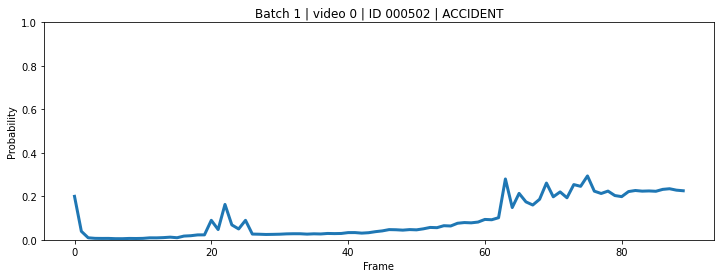

   plotting accident video 1  (ID 000490)


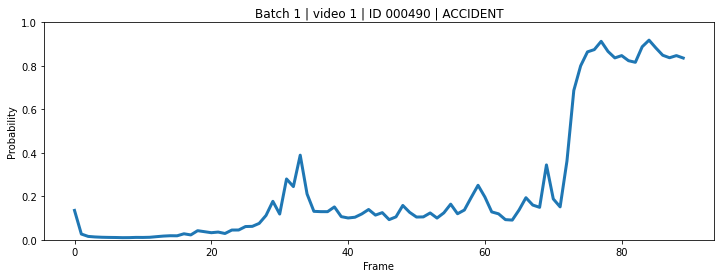

=== Batch 2 ===
   plotting accident video 4  (ID 000474)


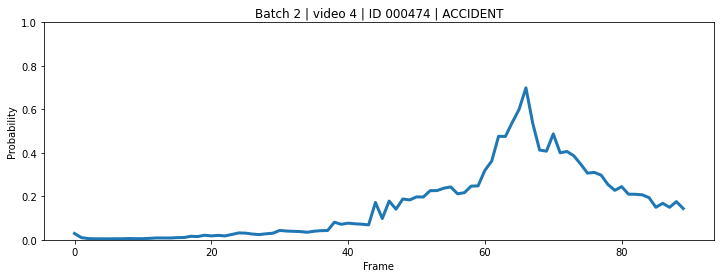

   plotting accident video 6  (ID 000500)


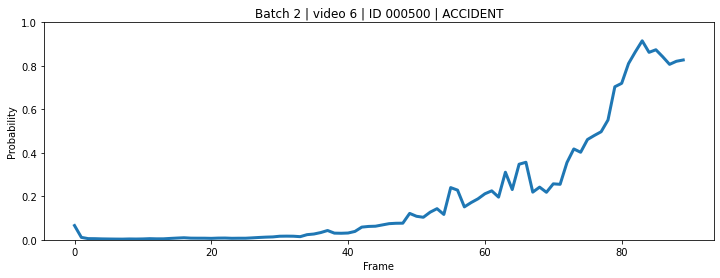

   plotting accident video 7  (ID 000489)


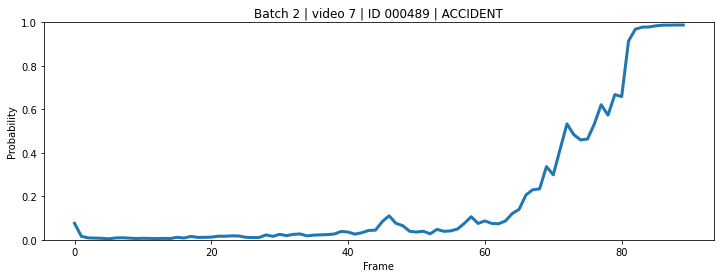

   plotting accident video 8  (ID 000498)


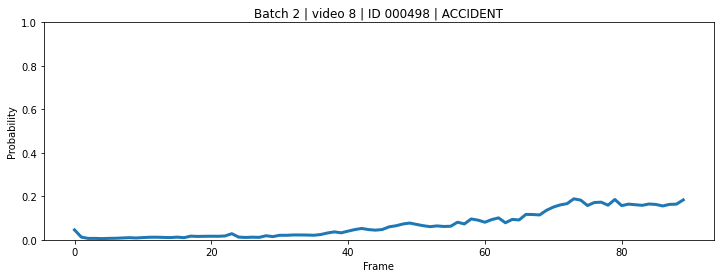


Done.


In [11]:
vis(default_model_path, max_batches=2)